# Loi d'Okun aux États-Unis : le PIB réel explique-t-il la variation du chômage ?

**Auteur :** Fatima Zahra HAJJI — **Cours :** Machine Learning (S7) — **Algorithme :** Régression linéaire simple (*Linear Regression*)

## 1. Présentation du projet
Ce projet étudie la relation entre la croissance économique et le chômage aux États-Unis à travers la **loi d'Okun** : lorsque l'économie croît plus vite que son rythme habituel, le chômage tend à baisser, et inversement.

## 2. Problématique
> **Dans quelle mesure la croissance du PIB réel permet-elle d'expliquer la variation du taux de chômage aux États-Unis ?**

## 3. Objectif mesurable
1. Estimer le coefficient d'Okun $\beta$ du modèle $\Delta U_t = \alpha + \beta\, g_t + \varepsilon_t$ (attendu : $\beta < 0$).
2. Vérifier que la régression linéaire **fait mieux qu'une référence naïve** (prédire la moyenne d'entraînement) sur un **test chronologique**, avec MAE, RMSE et R².
3. Quantifier la part de variance de $\Delta U$ expliquée hors échantillon (R² test) et analyser où le modèle se trompe.

## 4. Données (FRED – Federal Reserve Economic Data)
| Série | Contenu | Source primaire | Fréquence d'origine |
|---|---|---|---|
| `GDPC1` | PIB réel (milliards de dollars enchaînés 2017, taux annuel désaisonnalisé) | BEA | trimestrielle |
| `UNRATE` | Taux de chômage civil (%) désaisonnalisé | BLS | mensuelle |

## 5. Méthodologie
Apprentissage supervisé, **régression**.
- Variable explicative $X$ : $g_t$ = taux de croissance trimestriel du PIB réel (en %, **non annualisé**) $= 100\times(GDPC1_t / GDPC1_{t-1} - 1)$.
- Variable cible $Y$ : $\Delta U_t = U_t - U_{t-1}$, variation trimestrielle du taux de chômage (en points de pourcentage), $U_t$ étant la **moyenne trimestrielle** de `UNRATE`.
- Découpage **chronologique** (jamais aléatoire) : entraînement → validation → test.

In [9]:
# --- Environnement et reproductibilité ---
import sys, json, os, datetime as dt
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

print("Python      :", sys.version.split()[0])
for lib in (np, pd, matplotlib, sklearn, scipy):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
matplotlib  : 3.10.0
sklearn     : 1.6.1
scipy       : 1.16.3


## 6. Chargement et description des données
Les séries sont téléchargées depuis l'export CSV public de FRED, puis **sauvegardées dans `data/`** pour que le projet soit reproductible hors ligne et versionné (commit 1). Si les fichiers existent déjà, ils sont relus localement. En cas d'échec réseau, déposez manuellement `GDPC1.csv` et `UNRATE.csv` (téléchargés depuis la page FRED de chaque série) dans `data/`.

In [10]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

path_gdp = '/content/drive/MyDrive/F16_loi_Okun/data/GDPC1.csv'
df_gdp = pd.read_csv(path_gdp)

df_gdp.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,observation_date,GDPC1
0,1947-01-01,2182.681
1,1947-04-01,2176.892
2,1947-07-01,2172.432
3,1947-10-01,2206.452
4,1948-01-01,2239.682


In [11]:

path_unrate = '/content/drive/MyDrive/F16_loi_Okun/data/UNRATE.csv'
df_unrate = pd.read_csv(path_unrate)

df_unrate.head()

,observation_date,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5


### Dictionnaire de données
| Variable | Définition | Unité | Rôle |
|---|---|---|---|
| `GDPC1` | PIB réel américain | Mds de \$ enchaînés 2017, taux annuel CVS | brut |
| `UNRATE` | Taux de chômage civil | % de la population active, CVS | brut |
| `unrate_q` | Moyenne trimestrielle de `UNRATE` | % | intermédiaire |
| `gdp_growth` ($g_t$) | Croissance trimestrielle du PIB réel, non annualisée | % | **X** |
| `d_unrate` ($\Delta U_t$) | Variation trimestrielle du chômage | points de % | **Y** |

**Choix à documenter :** `UNRATE` est mensuelle ; on la ramène au trimestre par la **moyenne des trois mois** (le PIB est aussi une mesure de flux sur le trimestre). Une autre convention (dernier mois du trimestre) donnerait des résultats légèrement différents.

In [12]:
# --- Préparation des index temporels ---
# Conversion de la colonne date en type Datetime et définition en tant qu'index
df_unrate_temp = df_unrate.copy()
df_unrate_temp["observation_date"] = pd.to_datetime(df_unrate_temp["observation_date"])
df_unrate_temp = df_unrate_temp.set_index("observation_date")

df_gdp_temp = df_gdp.copy()
df_gdp_temp["observation_date"] = pd.to_datetime(df_gdp_temp["observation_date"])
df_gdp_temp = df_gdp_temp.set_index("observation_date")

# --- Construction du jeu trimestriel ---
unrate_series = df_unrate_temp["UNRATE"]
gdp_series = df_gdp_temp["GDPC1"]

unrate_q = unrate_series.resample("QS").mean()          # QS = début de trimestre, comme les dates de GDPC1
n_months = unrate_series.resample("QS").count()
unrate_q = unrate_q[n_months == 3]               # on écarte un trimestre final incomplet (moins de 3 mois)

df = pd.concat({"GDPC1": gdp_series, "unrate_q": unrate_q}, axis=1).dropna()
df["gdp_growth"] = 100 * df["GDPC1"].pct_change()
df["d_unrate"] = df["unrate_q"].diff()
df = df.dropna()                                  # supprime la 1re ligne (pas de retard disponible)

print("Dimensions :", df.shape)
print("Période    :", df.index.min().date(), "→", df.index.max().date())
display(df.head())
display(df.tail())
display(df.describe().T)

Dimensions : (313, 4)
Période    : 1948-04-01 → 2026-07-01


,GDPC1,unrate_q,gdp_growth,d_unrate
observation_date,,,,
1948-04-01,2276.690,3.666667,1.652377,-0.066667
1948-07-01,2289.770,3.766667,0.574518,0.100000
1948-10-01,2292.364,3.833333,0.113286,0.066667
1949-01-01,2260.807,4.666667,-1.376614,0.833333
1949-04-01,2253.128,5.866667,-0.339657,1.200000


,GDPC1,unrate_q,gdp_growth,d_unrate
observation_date,,,,
2025-04-01,23884.563,4.200000,0.990900,0.066667
2025-07-01,24112.966,4.333333,0.956279,0.133333
2026-01-01,24274.383,4.333333,0.669420,0.000000
2026-04-01,24408.011,4.266667,0.550490,-0.066667
2026-07-01,24611.077,4.133333,0.831965,-0.133333


,count,mean,std,min,25%,50%,75%,max
GDPC1,313.0,10546.534942,6415.912245,2253.128000,4956.477000,9083.256000,16353.835000,24611.077000
unrate_q,313.0,5.661661,1.696498,2.566667,4.300000,5.466667,6.700000,13.000000
gdp_growth,313.0,0.774829,1.108627,-7.876784,0.321124,0.774519,1.197502,7.762279
d_unrate,313.0,0.001278,0.692768,-4.200000,-0.200000,-0.066667,0.133333,9.166667


**Commit 1 (à faire maintenant)** : `git add data/ okun_projet.ipynb && git commit -m "Chargement et description des données FRED"`

## 7. Exploration et prétraitement

### 7.1 Qualité des données
On contrôle valeurs manquantes, doublons, types et valeurs extrêmes (règle de Tukey) avant toute modélisation.

In [13]:
print("Types :\n", df.dtypes, "\n")
print("Valeurs manquantes :\n", df.isna().sum(), "\n")
print("Doublons d'index :", df.index.duplicated().sum())

for col in ["gdp_growth", "d_unrate"]:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)]
    print(f"\nValeurs extrêmes (Tukey) pour {col} : {len(out)} trimestres sur {len(df)}")
    display(out[[col]].sort_values(col).head(8))

Types :
 GDPC1         float64
unrate_q      float64
gdp_growth    float64
d_unrate      float64
dtype: object 

Valeurs manquantes :
 GDPC1         0
unrate_q      0
gdp_growth    0
d_unrate      0
dtype: int64 

Doublons d'index : 0

Valeurs extrêmes (Tukey) pour gdp_growth : 22 trimestres sur 313


,gdp_growth
observation_date,
2020-04-01,-7.876784
1958-01-01,-2.595904
2008-10-01,-2.189027
1980-04-01,-2.060435
1982-01-01,-1.553645
1953-10-01,-1.513719
1949-01-01,-1.376614
2020-01-01,-1.316322



Valeurs extrêmes (Tukey) pour d_unrate : 32 trimestres sur 313


,d_unrate
observation_date,
2020-07-01,-4.200000
2020-10-01,-2.033333
1958-10-01,-0.966667
1950-07-01,-0.933333
2021-10-01,-0.900000
2021-07-01,-0.866667
1983-10-01,-0.833333
1950-04-01,-0.833333


### 7.2 Figure 1 – Les deux séries brutes

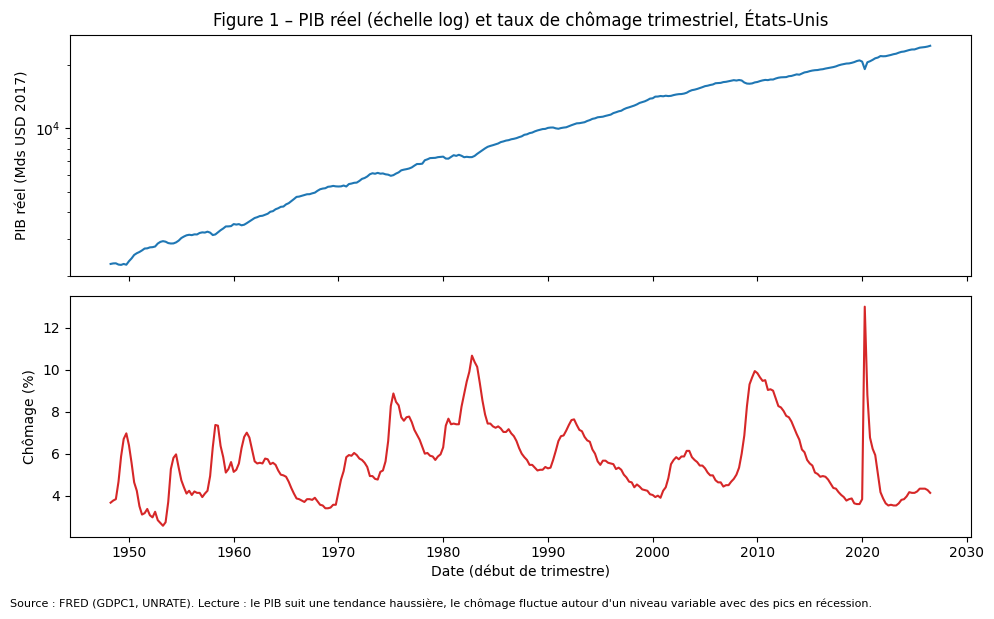

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(df.index, df["GDPC1"]); ax[0].set_ylabel("PIB réel (Mds USD 2017)"); ax[0].set_yscale("log")
ax[1].plot(df.index, df["unrate_q"], color="tab:red"); ax[1].set_ylabel("Chômage (%)")
ax[0].set_title("Figure 1 – PIB réel (échelle log) et taux de chômage trimestriel, États-Unis")
ax[1].set_xlabel("Date (début de trimestre)")
fig.text(0.01, -0.02, "Source : FRED (GDPC1, UNRATE). Lecture : le PIB suit une tendance haussière, le chômage fluctue autour d'un niveau variable avec des pics en récession.", fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig1_series.png", dpi=150, bbox_inches="tight"); plt.show()

**Lecture de la Figure 1.** Les niveaux ne sont pas directement comparables (le PIB est tendanciel, non stationnaire) : c'est la raison pour laquelle la loi d'Okun est estimée **en variations** (croissance vs. variation du chômage). Décrivez ici, après exécution, les épisodes visibles (récessions, 2008-2009, 2020).

### 7.3 Figure 2 – Croissance du PIB et variation du chômage dans le temps

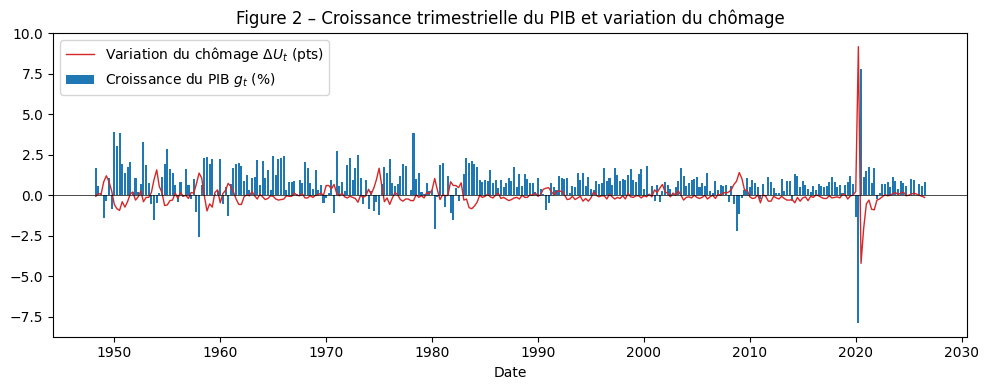

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(df.index, df["gdp_growth"], width=70, color="tab:blue", label="Croissance du PIB $g_t$ (%)")
ax.plot(df.index, df["d_unrate"], color="tab:red", lw=1, label="Variation du chômage $\\Delta U_t$ (pts)")
ax.axhline(0, color="k", lw=.5); ax.legend()
ax.set_title("Figure 2 – Croissance trimestrielle du PIB et variation du chômage")
ax.set_xlabel("Date"); plt.tight_layout()
plt.savefig("figures/fig2_variations.png", dpi=150, bbox_inches="tight"); plt.show()

**Lecture de la Figure 2.** Les deux séries doivent évoluer en sens inverse (barres négatives ↔ pics rouges positifs). Repérez les trimestres extrêmes (notamment 2020) : ils pèsent fortement sur une régression linéaire par moindres carrés.

### 7.4 Figure 3 – Nuage de points (relation d'Okun)

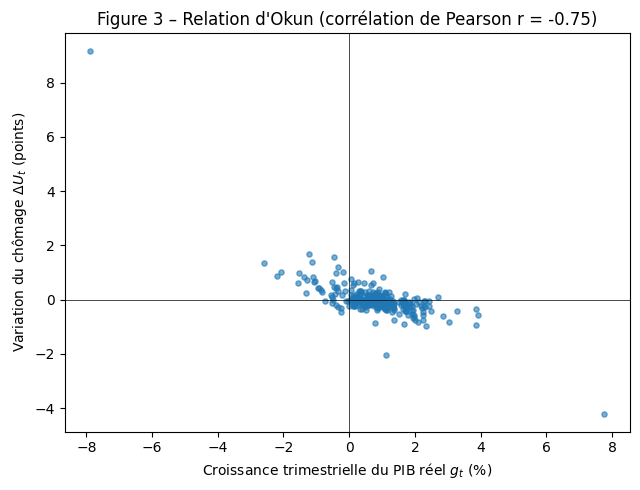

Pearson r = -0.753 (p = 2.2e-58) – mesure d'association, pas de causalité.


In [16]:
r, p = stats.pearsonr(df["gdp_growth"], df["d_unrate"])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(df["gdp_growth"], df["d_unrate"], s=14, alpha=.6)
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
ax.set_xlabel("Croissance trimestrielle du PIB réel $g_t$ (%)")
ax.set_ylabel("Variation du chômage $\\Delta U_t$ (points)")
ax.set_title(f"Figure 3 – Relation d'Okun (corrélation de Pearson r = {r:.2f})")
plt.tight_layout(); plt.savefig("figures/fig3_scatter.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Pearson r = {r:.3f} (p = {p:.2g}) – mesure d'association, pas de causalité.")

**Lecture de la Figure 3.** Chaque point est un trimestre. Une pente descendante confirme le signe attendu de la loi d'Okun ; la dispersion autour de la tendance indique la part de $\Delta U$ **non** expliquée par le PIB (délais d'ajustement de l'emploi, productivité, participation au marché du travail…). Les points isolés (récessions, 2020) sont des points à fort levier.

### 7.5 Découpage chronologique et pipeline sans fuite d'information
- **Entraînement** : jusqu'à 2009-T4 — **Validation** : 2010-T1 à 2016-T4 — **Test** : 2017-T1 → fin des données (touché **une seule fois**, à la fin).
- Le prétraitement (ici l'imputation par la médiane, inutile s'il n'y a pas de manquants mais incluse par robustesse) est **ajusté sur l'entraînement uniquement** grâce à un `Pipeline` scikit-learn.
- Le test contient le choc de 2020 : on rapporte donc aussi un score **hors 2020-2021** comme analyse de sensibilité (sans modifier le modèle).

In [17]:
X = df[["gdp_growth"]]
y = df["d_unrate"]

train = df.index <= "2009-12-31"
val   = (df.index >= "2010-01-01") & (df.index <= "2016-12-31")
test  = df.index >= "2017-01-01"

X_tr, y_tr = X[train], y[train]
X_va, y_va = X[val],   y[val]
X_te, y_te = X[test],  y[test]
print(f"train={len(X_tr)}  val={len(X_va)}  test={len(X_te)}")
assert X_tr.index.max() < X_va.index.min() < X_va.index.max() < X_te.index.min()   # ordre chronologique strict

def make_pipeline(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", model)])

train=247  val=28  test=38


**Commit 2 (après la section suivante)** : `git commit -am "Modèle de régression et évaluation"`

## 8. Modèle et évaluation

### 8.1 Référence naïve et régression linéaire
- **Référence naïve** : `DummyRegressor(strategy="mean")` prédit toujours la moyenne de $\Delta U$ de l'entraînement (aucune information sur le PIB).
- **Régression linéaire simple** : $\hat{\Delta U}_t = \hat\alpha + \hat\beta\, g_t$ estimée par moindres carrés (aucun hyperparamètre ; $\alpha,\beta$ sont les **paramètres** appris).
- Métriques : $MAE=\frac1n\sum|y_i-\hat y_i|$, $RMSE=\sqrt{\frac1n\sum(y_i-\hat y_i)^2}$, $R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$. Un $R^2$ test peut être **négatif** si le modèle prédit moins bien que la moyenne du test.

In [18]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

models = {"Référence naïve (moyenne)": make_pipeline(DummyRegressor(strategy="mean")),
          "Régression linéaire":        make_pipeline(LinearRegression())}

# 1) Validation : ajustement sur train, comparaison sur val (sert à décider, pas à tester)
rows = []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    rows.append({"Modèle": name, "Jeu": "validation", **metrics(y_va, m.predict(X_va))})
res_val = pd.DataFrame(rows).set_index(["Modèle", "Jeu"])
display(res_val.round(3))

,,MAE,RMSE,R2
Modèle,Jeu,,,
Référence naïve (moyenne),validation,0.211,0.253,-2.193
Régression linéaire,validation,0.284,0.334,-4.574


In [19]:
# 2) Évaluation finale : réajustement sur train+val (tout le passé), puis UN SEUL passage sur le test
X_tv, y_tv = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])
mask_hors_covid = ~((X_te.index >= "2020-01-01") & (X_te.index <= "2021-12-31"))

rows, preds = [], {}
for name, m in models.items():
    m.fit(X_tv, y_tv)
    p = m.predict(X_te); preds[name] = p
    rows.append({"Modèle": name, "Jeu": "test complet", **metrics(y_te, p)})
    rows.append({"Modèle": name, "Jeu": "test hors 2020-2021", **metrics(y_te[mask_hors_covid], p[mask_hors_covid])})
res_test = pd.DataFrame(rows).set_index(["Modèle", "Jeu"])
display(res_test.round(3))
res_test.round(4).to_csv("figures/tableau_resultats_test.csv")

MAE   RMSE     R2
Modèle                    Jeu                                     
Référence naïve (moyenne) test complet         0.564  1.688 -0.000
                          test hors 2020-2021  0.106  0.133 -0.121
Régression linéaire       test complet         0.470  1.224  0.474
                          test hors 2020-2021  0.154  0.197 -1.434

### 8.2 Coefficient d'Okun et intervalle de confiance
L'intervalle de confiance ci-dessous vient d'un MCO classique (`scipy.stats.linregress`) : il suppose des erreurs indépendantes et de variance constante, hypothèses **douteuses** sur des séries temporelles (autocorrélation, hétéroscédasticité) ; il est donc **indicatif** et probablement trop étroit.

In [20]:
lr = models["Régression linéaire"].named_steps["model"]          # modèle réajusté sur train+val
alpha_hat, beta_hat = lr.intercept_, lr.coef_[0]
reg = stats.linregress(X_tv["gdp_growth"], y_tv)
tcrit = stats.t.ppf(0.975, df=len(X_tv) - 2)
ci = (reg.slope - tcrit*reg.stderr, reg.slope + tcrit*reg.stderr)
g_neutre = -alpha_hat / beta_hat if beta_hat != 0 else np.nan

print(f"α̂ (ordonnée)      = {alpha_hat:.3f} pt/trimestre")
print(f"β̂ (coef. d'Okun) = {beta_hat:.3f}  IC95% indicatif [{ci[0]:.3f} ; {ci[1]:.3f}]")
print(f"Interprétation : +1 point de croissance trimestrielle ↔ {beta_hat:+.2f} pt de chômage en moyenne.")
print(f"Croissance trimestrielle 'neutre' (ΔU prédit = 0) : {g_neutre:.2f} %")

α̂ (ordonnée)      = 0.224 pt/trimestre
β̂ (coef. d'Okun) = -0.279  IC95% indicatif [-0.314 ; -0.244]
Interprétation : +1 point de croissance trimestrielle ↔ -0.28 pt de chômage en moyenne.
Croissance trimestrielle 'neutre' (ΔU prédit = 0) : 0.80 %


### 8.3 Analyse des erreurs

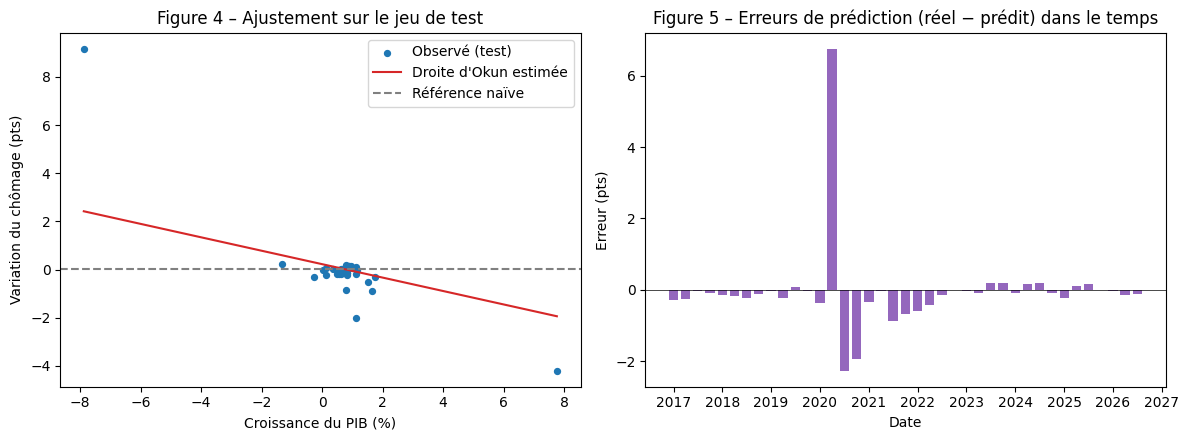

Les 5 plus grosses erreurs absolues sur le test :


,y_reel,y_pred,erreur,abs_erreur
observation_date,,,,
2020-04-01,9.17,2.42,6.75,6.75
2020-07-01,-4.20,-1.94,-2.26,2.26
2020-10-01,-2.03,-0.09,-1.94,1.94
2021-07-01,-0.87,0.01,-0.87,0.87
2021-10-01,-0.90,-0.24,-0.66,0.66


In [21]:
best = "Régression linéaire"
err = pd.DataFrame({"y_reel": y_te, "y_pred": preds[best]}, index=y_te.index)
err["erreur"] = err["y_reel"] - err["y_pred"]
err["abs_erreur"] = err["erreur"].abs()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(X_te["gdp_growth"], y_te, s=18, label="Observé (test)")
grid = pd.DataFrame({"gdp_growth": np.linspace(df["gdp_growth"].min(), df["gdp_growth"].max(), 100)})
ax[0].plot(grid["gdp_growth"], models[best].predict(grid), color="tab:red", label="Droite d'Okun estimée")
ax[0].axhline(models["Référence naïve (moyenne)"].predict(grid[:1])[0], color="gray", ls="--", label="Référence naïve")
ax[0].set_xlabel("Croissance du PIB (%)"); ax[0].set_ylabel("Variation du chômage (pts)")
ax[0].set_title("Figure 4 – Ajustement sur le jeu de test"); ax[0].legend()

ax[1].bar(err.index, err["erreur"], width=70, color="tab:purple")
ax[1].axhline(0, color="k", lw=.5)
ax[1].set_title("Figure 5 – Erreurs de prédiction (réel − prédit) dans le temps")
ax[1].set_xlabel("Date"); ax[1].set_ylabel("Erreur (pts)")
plt.tight_layout(); plt.savefig("figures/fig4_5_erreurs.png", dpi=150, bbox_inches="tight"); plt.show()

print("Les 5 plus grosses erreurs absolues sur le test :")
display(err.sort_values("abs_erreur", ascending=False).head(5).round(2))

**Comment lire les Figures 4 et 5.** Figure 4 : la droite rouge est la loi d'Okun estimée, la ligne grise est la référence naïve ; plus les points sont proches de la droite que de la ligne grise, plus le PIB apporte d'information. Figure 5 : des erreurs concentrées sur quelques trimestres signalent des chocs que le modèle linéaire ne capture pas ; des erreurs de même signe consécutives signalent de l'autocorrélation (le chômage réagit avec retard).

## 9. Compte rendu

In [22]:
rl  = res_test.loc[("Régression linéaire", "test complet")]
nv  = res_test.loc[("Référence naïve (moyenne)", "test complet")]
rl2 = res_test.loc[("Régression linéaire", "test hors 2020-2021")]
nv2 = res_test.loc[("Référence naïve (moyenne)", "test hors 2020-2021")]
print(f"- Coefficient d'Okun estimé β̂ = {beta_hat:.3f} (IC95% indicatif [{ci[0]:.3f}; {ci[1]:.3f}]).")
print(f"- Test complet : RMSE {rl.RMSE:.3f} (régression) vs {nv.RMSE:.3f} (naïf) ; R² = {rl.R2:.3f}.")
print(f"- Test hors 2020-2021 : RMSE {rl2.RMSE:.3f} vs {nv2.RMSE:.3f} ; R² = {rl2.R2:.3f}.")
print("- La régression bat la référence naïve en RMSE sur le test complet :", bool(rl.RMSE < nv.RMSE))

- Coefficient d'Okun estimé β̂ = -0.279 (IC95% indicatif [-0.314; -0.244]).
- Test complet : RMSE 1.224 (régression) vs 1.688 (naïf) ; R² = 0.474.
- Test hors 2020-2021 : RMSE 0.197 vs 0.133 ; R² = -1.434.
- La régression bat la référence naïve en RMSE sur le test complet : True


### Conclusion
*(À rédiger après exécution, en reprenant les valeurs imprimées ci-dessus — ne recopier aucun chiffre non produit par le notebook.)* Structure suggérée : (1) le signe et l'ordre de grandeur de $\beta$ sont-ils conformes à la loi d'Okun ? (2) la régression bat-elle la référence naïve, et de combien en RMSE/MAE ? (3) quelle part de la variance de $\Delta U$ est expliquée hors échantillon (R² test) avec et sans 2020-2021 ? (4) réponse à la problématique en une phrase nuancée.

### Limites
- **Association, pas causalité** : la régression décrit une corrélation conditionnelle ; chômage et PIB s'influencent mutuellement.
- **Modèle minimal** : une seule variable explicative, relation supposée linéaire et stable ; la loi d'Okun a un coefficient qui varie selon les périodes (changements structurels, productivité, participation).
- **Effets retardés** : le chômage réagit au PIB avec délai ; l'absence de retards ($g_{t-1}$, $\Delta U_{t-1}$) est une limite (extension possible).
- **Choc 2020** : trimestres extrêmes à fort levier ; l'évaluation hors 2020-2021 n'est qu'une analyse de sensibilité, pas une correction.
- **Mesure** : `UNRATE` ramenée au trimestre par moyenne ; `GDPC1` est révisé par la BEA (le jeu téléchargé est un millésime à une date donnée, d'où l'importance de la date de consultation) ; croissance non annualisée.
- **Inférence** : l'IC des MCO ignore l'autocorrélation des résidus ; un test de significativité rigoureux demanderait des erreurs robustes (HAC).
- **Échantillon de test court** et en une seule période : les scores ont une forte incertitude.

### Références
- FRED, Federal Reserve Bank of St. Louis — GDPC1 : https://fred.stlouisfed.org/series/GDPC1 ; UNRATE : https://fred.stlouisfed.org/series/UNRATE (voir les conditions d'utilisation de chaque série sur la page FRED).
- Okun, A. M. (1962). *Potential GNP: Its Measurement and Significance*. Cowles Foundation.
- Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12.

### Usage d'une IA
Une IA générative (Claude, Anthropic) a été utilisée pour structurer le notebook et rédiger le code initial ; le code, les résultats et leur interprétation doivent être relus, exécutés et compris par l'auteure.

**Commit 3 + tag :** `git add -A && git commit -m "Version finale" && git tag remise-finale`